In [1]:
from torch import nn
import torch
from d2l import torch as d2l

In [2]:
def masked_softmax(X,valid_lens):
    if valid_lens is None:
        return nn.functional.softmax(X,dim=-1)
    if valid_lens.dim()==1:
        valid_lens=torch.repeat_interleave(valid_lens,X.shape[1])
    else:
        valid_lens=valid_lens.reshape(-1)
    shape = X.shape
    X = d2l.sequence_mask(X.reshape(-1, shape[-1]), valid_lens,  value=-1e6)

    return torch.softmax(X,dim=-1).reshape(shape)


class AddtiveAttention(nn.Module):
    def __init__(self,query_size,key_size,hidden_size,drop_out):
        super().__init__()
        self.W_k=nn.Linear(key_size,hidden_size,bias=False)
        self.W_q=nn.Linear(query_size,hidden_size,bias=False)
        self.W_v=nn.Linear(hidden_size,1,bias=False)
        self.drop_out=nn.Dropout(drop_out)

    def forward(self,query:torch.Tensor,key:torch.Tensor,value:torch.Tensor,valid_lens:torch.Tensor):
        '''
        query:[batch_size,num_q,query_size]
        key:[batch_size,num_k,key_size]
        value:[batch_size,num_k,value_size]
        '''
        query_h,key_h=self.W_q(query),self.W_k(key)
        query_h=torch.unsqueeze(query_h,dim=2)
        key_h=torch.unsqueeze(key_h,dim=1)
        hid=torch.tanh(query_h+key_h)
        attention_weight=masked_softmax(self.W_v(hid).squeeze(-1),valid_lens)

        return torch.bmm(self.drop_out(attention_weight),value)


query=torch.randn([1,5,5])
key=torch.randn([1,6,7])
value=torch.randn([1,6,9])
valid_lens=torch.tensor([5])
aa=AddtiveAttention(query_size=5,key_size=7,hidden_size=10,drop_out=0.1)
aa(query,key,value,valid_lens)

tensor([[[ 0.1411, -0.1391,  0.2022,  0.4100,  0.5135,  0.5144, -0.1718,
          -0.5525, -0.6310],
         [-0.1312, -0.0535,  0.7115,  0.5665, -0.0182,  0.0436, -0.4588,
          -0.1334, -0.6881],
         [-0.1567,  0.0237,  0.3139,  0.7171,  0.2397,  0.0549, -0.6473,
          -0.4618, -0.8847],
         [-0.0771, -0.0733,  0.6190,  0.6319,  0.3922,  0.3312, -0.6452,
          -0.5741, -1.0943],
         [ 0.1777, -0.1700,  0.2386,  0.1890,  0.6234,  0.2745, -0.0320,
          -0.6592, -0.7579]]], grad_fn=<BmmBackward0>)

In [3]:
class AttentionDecoder2(d2l.AttentionDecoder):
    def __init__(self,vocab_size,embed_size,num_hiddens,num_layers,dropout=0):
        super().__init__()
        self.vocab_size=vocab_size
        self.embed_size=embed_size
        self.hidden_size=num_hiddens
        self.num_layers=num_layers

        self.addtive_attention=AddtiveAttention(num_hiddens,num_hiddens,num_hiddens,dropout)
        self.embedding=nn.Embedding(vocab_size,embed_size)
        self.rnn=nn.GRU(self.embed_size+num_hiddens,num_hiddens,num_layers)
        self.Linear=nn.Linear(self.hidden_size,self.vocab_size)
        return
    def init_state(self,enc_outputs,enc_valid_lens):
        ''' enc_outputs:[num_steps,batch_size,hidden_size]
            hidden_state:[num_layers,batch_size,hidden_size]
        '''
        outputs,hidden_state=enc_outputs
        return (outputs.permute([1,0,2]),hidden_state,enc_valid_lens)

    def forward(self,X,state):
        '''
        X=[batch_size,num_step,vocab_size]
        state=([batch_size,num_steps,hidden_size],[num_layers,batch_size,hidden_size],None)
        '''
        enc_outputs,hidden_state,enc_valid_lens=state
        X=self.embedding(X).permute([1,0,2])
        outputs,self._attention_weight=([],[])
        for x in X:
            context=self.addtive_attention(hidden_state[-1].unsqueeze(1),enc_outputs,enc_outputs,enc_valid_lens)
            x_in=torch.cat((context,x.unsqueeze(1)),dim=-1)
            out,hidden_state=self.rnn(x_in.permute(1,0,2),hidden_state)
            outputs.append(out)
            self._attention_weight.append(context)
        outputs=self.Linear(torch.cat(outputs,dim=0))
        return outputs.permute([1, 0, 2]), [enc_outputs, hidden_state,enc_valid_lens]

    @property
    def attention_weights(self):
        return self._attention_weight
    

In [4]:
encoder1=d2l.Seq2SeqEncoder(vocab_size=10,embed_size=8,num_hiddens=16,num_layers=2)
decoder1=AttentionDecoder2(vocab_size=10,embed_size=8,num_hiddens=16,num_layers=2)
encoder1.eval()
decoder1.eval()
X=torch.zeros((4,7),dtype=torch.long)
state = decoder1.init_state(encoder1(X),None) 
output, state = decoder1(X, state) 
output.shape, len(state), state[0].shape, len(state[1]), state[1][0].shape

#不要提前设置layer的dtype，不然会存在类型冲突无法计算。
#检查维度转换。

(torch.Size([4, 7, 10]), 3, torch.Size([4, 7, 16]), 2, torch.Size([4, 16]))

loss 0.018, 4103.8 tokens/sec on cuda:0


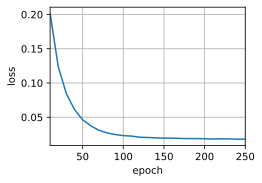

In [5]:
embed_size, num_hiddens, num_layers, dropout = 32, 32, 2, 0.1
batch_size, num_steps = 64, 10
lr, num_epochs, device = 0.005, 250, d2l.try_gpu()
train_iter, src_vocab, tgt_vocab = d2l.load_data_nmt(batch_size, num_steps)
encoder = d2l.Seq2SeqEncoder(
len(src_vocab), embed_size, num_hiddens, num_layers, dropout)
decoder = AttentionDecoder2(
len(tgt_vocab), embed_size, num_hiddens, num_layers, dropout)
net = d2l.EncoderDecoder(encoder, decoder)
d2l.train_seq2seq(net, train_iter, lr, num_epochs, tgt_vocab, device)

In [6]:
engs = ['go .', "i lost .", 'he\'s calm .', 'i\'m home .']
fras = ['va !', 'j\'ai perdu .', 'il est calme .', 'je suis chez moi .']
for eng, fra in zip(engs, fras):
    translation, dec_attention_weight_seq = d2l.predict_seq2seq(
net, eng, src_vocab, tgt_vocab, num_steps, device, True)
print(f'{eng} => {translation}, ',
f'bleu {d2l.bleu(translation, fra, k=2):.3f}')

i'm home . => je suis chez moi .,  bleu 1.000
